<a href="https://colab.research.google.com/github/KenPham0604/US_Accident_Severity_Prediction/blob/main/AblationRQ1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1 — SETUP
# Independent RQ1 Ablation Study

!pip install -q lightgbm shap

from google.colab import drive
drive.mount("/content/drive")

import os
import gc
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score)
from scipy.stats import spearmanr

pd.set_option("display.max_columns", None)

# CHANGE FILE PATH HERE

DATA_PATH = (
    "/content/drive/MyDrive/ADY201m/"
    "US_Accidents_cleaned.zip"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/ADY201m/"
    "RQ1_Ablation_Results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"File not found: {DATA_PATH}\n"
        "Check the extension and Google Drive path.")

# Experiment settings

SEED = 42

CHUNK_SIZE = 200_000
SAMPLE_FRAC = 0.04
MAX_ROWS = 250_000

SHAP_SAMPLE_SIZE = 2000
PERMUTATION_SAMPLE_SIZE = 10_000

CLASS_WEIGHT_CAP = 2.5

N_ESTIMATORS = 250
LEARNING_RATE = 0.05
NUM_LEAVES = 31

# File opener

from contextlib import contextmanager

@contextmanager
def open_dataset():

    if DATA_PATH.lower().endswith(".zip"):
        with zipfile.ZipFile(DATA_PATH, "r") as z:
            csv_files = [
                name for name in z.namelist()
                if name.lower().endswith(".csv")
                and not name.endswith("/")]
            if len(csv_files) != 1:
                raise ValueError(
                    f"Expected one CSV, found: {csv_files}")
            with z.open(csv_files[0]) as f:
                yield f
    else:
        yield DATA_PATH

print("Dataset:", DATA_PATH)
print("Output:", OUTPUT_DIR)
print("Seed:", SEED)
print("✅ Setup completed")

Mounted at /content/drive
Dataset: /content/drive/MyDrive/ADY201m/US_Accidents_cleaned_remove_distance.zip
Output: /content/drive/MyDrive/ADY201m/RQ1_Ablation_Results
Seed: 42
✅ Setup completed


In [ ]:
# 2 — LOAD CLEANED DATASET BY CHUNKING

# 1. Feature groups from RQ1

FEATURE_GROUPS = {
    "Geographic": [
        "State",
        "Street",
        "County",
        "Airport_Code",
        "Zipcode",
        "City",
        "Start_Lat",
        "Start_Lng",
        "Timezone"
    ],

    "Time": [
        "Year",
        "Month",
        "Hour",
        "DayOfWeek",
        "Season"
    ],

    "Infrastructure": [
        "Traffic_Signal",
        "Crossing",
        "Stop",
        "Station",
        "Junction",
        "Amenity",
        "Railway",
        "No_Exit",
        "Give_Way"
    ],

    "Weather": [
        "Temperature(F)",
        "Weather_Condition",
        "Wind_Direction",
        "Pressure(in)",
        "Wind_Speed(mph)",
        "Humidity(%)",
        "Visibility(mi)"
    ],

    "Light": [
        "Sunrise_Sunset",
        "Nautical_Twilight",
        "Astronomical_Twilight",
        "Civil_Twilight"
    ]
}

# 2. Inspect original columns

with open_dataset() as f:
    original_columns = pd.read_csv(
        f, nrows=0
    ).columns.tolist()

print("Original columns:", len(original_columns))
print(original_columns)

if "Start_Time" not in original_columns:
    raise ValueError("Start_Time column not found.")

if "Severity" not in original_columns:
    raise ValueError("Severity column not found.")

# Time variables will be derived later
derived_time = FEATURE_GROUPS["Time"]

requested_features = [
    c
    for group, features in FEATURE_GROUPS.items()
    for c in features
    if c not in derived_time]

read_columns = [
    "Severity",
    "Start_Time"
] + [
    c for c in requested_features
    if c in original_columns
]

read_columns = list(dict.fromkeys(read_columns))

# Preserve categorical codes, ZIP codes, etc.
categorical_candidates = [
    "State", "Street", "County",
    "Airport_Code", "Zipcode", "City",
    "Timezone", "Weather_Condition",
    "Wind_Direction", "Sunrise_Sunset",
    "Nautical_Twilight",
    "Astronomical_Twilight",
    "Civil_Twilight"]

dtype_map = {
    c: "string"
    for c in categorical_candidates
    if c in read_columns}

missing_features = [
    c for c in requested_features
    if c not in original_columns]

print("\nMissing optional features:")
print(missing_features)

# 3. Read by chunks

sample_parts = []
total_read = 0

with open_dataset() as f:

    reader = pd.read_csv(
        f,
        usecols=read_columns,
        dtype=dtype_map,
        chunksize=CHUNK_SIZE,
        low_memory=False)

    for i, chunk in enumerate(reader):
        total_read += len(chunk)
        part = chunk.sample(
            frac=SAMPLE_FRAC,
            random_state=SEED + i)

        sample_parts.append(part)
        print(
            f"Chunk {i+1}: "
            f"{total_read:,} rows read")

df_sample = pd.concat(
    sample_parts,
    ignore_index=True)

del sample_parts
gc.collect()

# 4. Limit sample size

if len(df_sample) > MAX_ROWS:

    df_sample = df_sample.sample(
        n=MAX_ROWS,
        random_state=SEED
    ).reset_index(drop=True)

print("\n=== SAMPLE SUMMARY ===")
print("Rows:", len(df_sample))
print("Columns:", len(df_sample.columns))

display(df_sample.head(3))

Original columns: 34
['Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'Street', 'City', 'County', 'State', 'Zipcode', 'Timezone', 'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Weather_Condition', 'Amenity', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Station', 'Stop', 'Traffic_Signal', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight']

Missing optional features:
[]
Chunk 1: 200,000 rows read
Chunk 2: 400,000 rows read
Chunk 3: 600,000 rows read
Chunk 4: 800,000 rows read
Chunk 5: 1,000,000 rows read
Chunk 6: 1,200,000 rows read
Chunk 7: 1,400,000 rows read
Chunk 8: 1,600,000 rows read
Chunk 9: 1,800,000 rows read
Chunk 10: 2,000,000 rows read
Chunk 11: 2,200,000 rows read
Chunk 12: 2,400,000 rows read
Chunk 13: 2,600,000 rows read
Chunk 14: 2,800,000 rows read
Chunk 15: 3,000,000 rows read
Chunk 16: 3,200,000 rows read


,Severity,Start_Time,Start_Lat,Start_Lng,Street,City,County,State,Zipcode,Timezone,Airport_Code,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Weather_Condition,Amenity,Crossing,Give_Way,Junction,No_Exit,Railway,Station,Stop,Traffic_Signal,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,2,2021-10-26 17:40:42,42.344791,-71.080917,Saint Botolph St,Boston,Suffolk,MA,02115-4804,US/Eastern,KBOS,57.0,93.0,29.50,2.0,NE,28.0,Light Rain / Windy,False,True,False,False,False,False,False,True,False,1,1,1,1
1,3,2016-12-09 14:29:37,27.441572,-82.459206,I-75 N,Bradenton,Manatee,FL,34211,US/Eastern,KSRQ,62.1,56.0,30.21,10.0,NNE,12.7,Clear,False,False,False,False,False,False,False,False,False,1,1,1,1
2,2,2019-11-04 14:22:00,33.870615,-117.544660,Corona Fwy S,Corona,Riverside,CA,92879,US/Pacific,KAJO,85.0,14.0,29.33,10.0,W,8.0,Fair,False,False,False,True,False,False,False,False,False,1,1,1,1


In [ ]:
# 3 — TIME FEATURE ENGINEERING
# AND BINARY TARGET CREATION

# 1. Parse Start_Time

df_sample["Start_Time"] = pd.to_datetime(
    df_sample["Start_Time"],
    errors="coerce",
    format="mixed")

df_sample["Severity"] = pd.to_numeric(
    df_sample["Severity"],
    errors="coerce")

# Keep valid records only
df_sample = df_sample.loc[
    df_sample["Start_Time"].notna()
    & df_sample["Severity"].isin([1, 2, 3, 4])
].copy()

# 2. Extract time features

dt = df_sample["Start_Time"]

df_sample["Year"] = dt.dt.year.astype("int16")
df_sample["Month"] = dt.dt.month.astype("int8")
df_sample["Hour"] = dt.dt.hour.astype("int8")

df_sample["DayOfWeek"] = (
    dt.dt.dayofweek.astype("int8"))

df_sample["Season"] = (
    (df_sample["Month"] % 12) // 3 + 1
).astype("int8")

# 3. Target

df_sample["Severity_High"] = (
    df_sample["Severity"] >= 3
).astype("int8")

# 4. Define final feature set

available_groups = {
    group: [
        c for c in features
        if c in df_sample.columns
    ]
    for group, features in FEATURE_GROUPS.items()}

all_features = [
    c
    for group, features in available_groups.items()
    for c in features]

# Check for duplicates
assert len(all_features) == len(set(all_features))

if "Year" not in all_features:
    raise ValueError("Year was not generated.")

if len(available_groups["Geographic"]) == 0:
    raise ValueError("No geographic features found.")

X = df_sample[all_features].copy()
y = df_sample["Severity_High"].copy()

# Save time values for temporal validation
years = df_sample["Year"].copy()

print("\n=== FEATURE GROUPS ===")

for group, features in available_groups.items():
    print(f"{group} ({len(features)}): {features}")

print("\n=== TARGET DISTRIBUTION ===")

display(
    y.value_counts(
        normalize=True
    ).sort_index() * 100)

print("\n=== DATASET SHAPE ===")
print("X:", X.shape)
print("y:", y.shape)

print("\n=== YEAR DISTRIBUTION ===")
display(years.value_counts().sort_index())


=== FEATURE GROUPS ===
Geographic (9): ['State', 'Street', 'County', 'Airport_Code', 'Zipcode', 'City', 'Start_Lat', 'Start_Lng', 'Timezone']
Time (5): ['Year', 'Month', 'Hour', 'DayOfWeek', 'Season']
Infrastructure (9): ['Traffic_Signal', 'Crossing', 'Stop', 'Station', 'Junction', 'Amenity', 'Railway', 'No_Exit', 'Give_Way']
Weather (7): ['Temperature(F)', 'Weather_Condition', 'Wind_Direction', 'Pressure(in)', 'Wind_Speed(mph)', 'Humidity(%)', 'Visibility(mi)']
Light (4): ['Sunrise_Sunset', 'Nautical_Twilight', 'Astronomical_Twilight', 'Civil_Twilight']

=== TARGET DISTRIBUTION ===


,proportion
Severity_High,
0,80.6044
1,19.3956



=== DATASET SHAPE ===
X: (250000, 34)
y: (250000,)

=== YEAR DISTRIBUTION ===


,count
Year,
2016,13333
2017,23466
2018,29167
2019,31013
2020,38053
2021,50728
2022,56442
2023,7798


In [ ]:
# 4 — FIXED DATA SPLIT
# Train 64% / Validation 16% / Test 20%

indices = np.arange(len(X))

# Use original 4-class Severity for stratification
severity_original = df_sample["Severity"].to_numpy()

dev_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=severity_original,
    random_state=SEED)

train_idx, val_idx = train_test_split(
    dev_idx,
    test_size=0.20,
    stratify=severity_original[dev_idx],
    random_state=SEED)

X_train = X.iloc[train_idx].reset_index(drop=True)
X_val = X.iloc[val_idx].reset_index(drop=True)
X_test = X.iloc[test_idx].reset_index(drop=True)

y_train = y.iloc[train_idx].reset_index(drop=True)
y_val = y.iloc[val_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)

# Development pool for seed stability / temporal validation
X_dev = X.iloc[dev_idx].reset_index(drop=True)
y_dev = y.iloc[dev_idx].reset_index(drop=True)
years_dev = years.iloc[dev_idx].reset_index(drop=True)

print("=== DATA SPLIT ===")

print("Train:", X_train.shape, "64%")
print("Validation:", X_val.shape, "16%")
print("Test:", X_test.shape, "20%")

print("\nPositive class distribution:")

for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)]:
    print(
        f"{name}: {target.mean()*100:.2f}%")

print("\n✅ Fixed split completed")
print("Test set will not be used for feature selection.")

=== DATA SPLIT ===
Train: (160000, 34) 64%
Validation: (40000, 34) 16%
Test: (50000, 34) 20%

Positive class distribution:
Train: 19.40%
Validation: 19.39%
Test: 19.39%

✅ Fixed split completed
Test set will not be used for feature selection.


In [ ]:

# 5 — PREPROCESSING + LIGHTGBM + SHAP

from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight

# 1. Categorical features

HIGH_CARD = [
    "Street",
    "City",
    "County",
    "Zipcode",
    "Airport_Code",
    "Weather_Condition"]

LOW_CARD = [
    "State",
    "Timezone",
    "Wind_Direction",
    "Sunrise_Sunset",
    "Civil_Twilight",
    "Nautical_Twilight",
    "Astronomical_Twilight"]

# 2. Convert numeric/boolean data

def numeric_series(series):

    numeric = pd.to_numeric(
        series,
        errors="coerce")

    # Convert True / False stored as text
    boolean_values = (
        series.astype("string")
        .str.strip()
        .str.lower()
        .map({
            "true": 1.0,
            "false": 0.0}))

    numeric = numeric.where(
        numeric.notna(),
        boolean_values)

    return numeric.astype("float32")

# 3. Train-only preprocessing

def preprocess_features(Xtr, Xva, features):

    train_blocks = []
    valid_blocks = []

    # Each encoded column maps back to one original feature
    feature_origins = []

    low_features = [
        c for c in features
        if c in LOW_CARD]

    other_features = [
        c for c in features
        if c not in LOW_CARD]

    for c in other_features:

        # Frequency Encoding

        if c in HIGH_CARD:

            tr = (
                Xtr[c].fillna("MISSING")
                .astype(str)
                .str.strip())

            va = (
                Xva[c].fillna("MISSING")
                .astype(str)
                .str.strip())

            freq_map = tr.value_counts(
                normalize=True)

            train_col = (
                tr.map(freq_map)
                .fillna(0)
                .to_numpy(dtype=np.float32))

            valid_col = (
                va.map(freq_map)
                .fillna(0)
                .to_numpy(dtype=np.float32))

        # Numeric and Boolean variables

        else:

            tr = numeric_series(Xtr[c])
            va = numeric_series(Xva[c])

            median = tr.median()

            if pd.isna(median):
                median = 0.0

            train_col = (
                tr.fillna(median)
                .to_numpy(dtype=np.float32))

            valid_col = (
                va.fillna(median)
                .to_numpy(dtype=np.float32))

        train_blocks.append(train_col.reshape(-1, 1))
        valid_blocks.append(valid_col.reshape(-1, 1))

        feature_origins.append(c)

    # 4. One-Hot Encoding, fit on train only

    if low_features:

        train_low = (
            Xtr[low_features]
            .fillna("MISSING")
            .astype(str))

        valid_low = (
            Xva[low_features]
            .fillna("MISSING")
            .astype(str))

        encoder = OneHotEncoder(
            handle_unknown="ignore",
            max_categories=30,
            sparse_output=False,
            dtype=np.float32)

        low_train_encoded = encoder.fit_transform(train_low)

        low_valid_encoded = encoder.transform(valid_low)

        train_blocks.append(low_train_encoded)
        valid_blocks.append(low_valid_encoded)

        # Recover original feature for each OHE column
        encoded_names = encoder.get_feature_names_out(low_features)

        for name in encoded_names:

            original = next(
                c for c in low_features
                if name.startswith(c + "_"))

            feature_origins.append(original)

    # 5. Create encoded DataFrames

    Xtr_array = np.concatenate(
        train_blocks, axis=1
    ).astype(np.float32)

    Xva_array = np.concatenate(
        valid_blocks, axis=1
    ).astype(np.float32)

    encoded_names = [
        f"f{i:04d}"
        for i in range(Xtr_array.shape[1])]

    Xtr_encoded = pd.DataFrame(
        Xtr_array,
        columns=encoded_names)

    Xva_encoded = pd.DataFrame(
        Xva_array,
        columns=encoded_names)

    assert (
        len(feature_origins)
        == Xtr_encoded.shape[1])

    return (
        Xtr_encoded,
        Xva_encoded,
        feature_origins)

# 6. Capped class weights

def get_sample_weights(y):

    classes = np.unique(y)

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=np.asarray(y))

    weights = np.minimum(
        weights,
        weights.min() * CLASS_WEIGHT_CAP)

    weight_dict = dict(zip(classes, weights))

    return np.asarray(
        [weight_dict[value] for value in y],
        dtype=np.float32)

# 7. LightGBM

def create_model(seed=SEED):

    return lgb.LGBMClassifier(
        n_estimators=N_ESTIMATORS,
        learning_rate=LEARNING_RATE,
        num_leaves=NUM_LEAVES,
        n_jobs=-1,
        random_state=seed,
        device_type="cpu",
        verbosity=-1)

# 8. Model metrics

def calculate_metrics(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Macro_Precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0),

        "Macro_Recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0),

        "Macro_F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0),

        "Recall_High": recall_score(
            y_true, y_pred,
            pos_label=1,
            zero_division=0)}


# 9. Mean Absolute SHAP by ORIGINAL feature
#    + Grouped Net SHAP by FACTOR GROUP

def calculate_shap(
    model,
    X_encoded,
    feature_origins,
    n_samples=SHAP_SAMPLE_SIZE,
    seed=SEED):

    X_shap = X_encoded.sample(
        n=min(n_samples, len(X_encoded)),
        random_state=seed)

    # LightGBM native TreeSHAP, binary classification
    # For positive class 1, contributions are
    # in raw-score/log-odds space.
    contributions = model.booster_.predict(
        X_shap,
        pred_contrib=True)

    if hasattr(contributions, "toarray"):
        contributions = contributions.toarray()

    contributions = np.asarray(contributions)

    n_features = X_encoded.shape[1]

    if contributions.shape[1] != n_features + 1:
        raise ValueError(
            f"Unexpected SHAP shape: {contributions.shape}")

    shap_values = contributions[:, :-1]

    # Group OHE contributions back to original features
    # Sum signed values first, then calculate mean(abs)

    original_names = list(dict.fromkeys(feature_origins))

    positions = {
        name: i
        for i, name in enumerate(original_names)}

    shap_aggregated = np.zeros(
        (len(X_shap), len(original_names)),
        dtype=np.float64)

    for j, original_feature in enumerate(
        feature_origins):

        pos = positions[original_feature]

        shap_aggregated[:, pos] += (shap_values[:, j])

    mean_abs_shap = (np.abs(shap_aggregated).mean(axis=0))

    shap_df = pd.DataFrame({
        "Feature": original_names,
        "Mean_Abs_SHAP": mean_abs_shap})

    shap_df = shap_df.sort_values(
        "Mean_Abs_SHAP",
        ascending=False
    ).reset_index(drop=True)

    shap_df["Rank"] = np.arange(
        1, len(shap_df) + 1)

    # Map each feature to its factor group
    group_mapping = {
        c: group
        for group, features in FEATURE_GROUPS.items()
        for c in features}

    shap_df["Group"] = (
        shap_df["Feature"].map(group_mapping))

    missing = shap_df.loc[
        shap_df["Group"].isna(), "Feature"
    ].tolist()

    if missing:
        raise ValueError(
            f"SHAP features missing from FEATURE_GROUPS: {missing}")

    # NEW: Grouped Net SHAP
    # Sum signed original-feature SHAP values per sample,
    # then compute mean absolute contribution for each group.

    original_feature_groups = [
        group_mapping[name]
        for name in original_names]

    group_net_records = []

    for group in FEATURE_GROUPS:

        indices = [
            j for j, g in enumerate(original_feature_groups)
            if g == group]

        if not indices:
            continue

        net_per_sample = (
            shap_aggregated[:, indices].sum(axis=1))

        group_net_records.append({
            "Group": group,
            "Grouped_Net_MeanAbs": float(
                np.abs(net_per_sample).mean())})

    group_net_df = pd.DataFrame(group_net_records)

    return shap_df, group_net_df

# 10. One reusable experiment function

def run_experiment(
    experiment_name,
    features,
    Xtr,
    ytr,
    Xva,
    yva,
    seed=SEED,
    compute_shap=True):

    # Preprocess only selected features
    Xtr_p, Xva_p, origins = preprocess_features(
        Xtr,
        Xva,
        features)

    model = create_model(seed)

    model.fit(
        Xtr_p,
        ytr,
        sample_weight=get_sample_weights(ytr))

    predictions = model.predict(Xva_p)

    metrics = calculate_metrics(
        yva,
        predictions)

    shap_df = None
    group_net_df = None

    if compute_shap:

        shap_df, group_net_df = calculate_shap(
            model,
            Xva_p,
            origins,
            seed=seed)

        shap_df["Experiment"] = experiment_name
        group_net_df["Experiment"] = experiment_name

    return {
        "Model": model,
        "Metrics": metrics,
        "SHAP": shap_df,
        "SHAP_Grouped": group_net_df,
        "X_val_encoded": Xva_p,
        "Feature_Origins": origins}


print("✅ Preprocessing and LightGBM functions ready")


✅ Preprocessing and LightGBM functions ready


In [ ]:

# 6 — MAIN ABLATION EXPERIMENT
# 1 seed, 4 model configurations

geographic_features = available_groups["Geographic"]

EXPERIMENTS = {
    "Full": all_features,

    "No_Year": [
        c for c in all_features
        if c != "Year"],

    "No_Geographic": [
        c for c in all_features
        if c not in geographic_features],

    "No_Both": [
        c for c in all_features
        if c != "Year"
        and c not in geographic_features]}

ablation_metrics = []
ablation_shap = []
ablation_group_net = []

# Keep only baseline model for permutation experiment
baseline_model = None
baseline_Xval = None
baseline_origins = None

for name, features in EXPERIMENTS.items():

    print("\n" + "=" * 60)
    print("EXPERIMENT:", name)
    print("Features:", len(features))
    print("=" * 60)

    result = run_experiment(
        experiment_name=name,
        features=features,
        Xtr=X_train,
        ytr=y_train,
        Xva=X_val,
        yva=y_val,
        seed=SEED,
        compute_shap=True)

    metrics = result["Metrics"]

    ablation_metrics.append({
        "Experiment": name,
        "N_Features": len(features),
        **metrics})

    shap_df = result["SHAP"]

    ablation_shap.append(shap_df)
    ablation_group_net.append(result["SHAP_Grouped"])

    print("\nMetrics:")
    display(pd.DataFrame([metrics]).round(4))

    print("\nTop 10 SHAP features:")
    display(
        shap_df[
            ["Rank", "Feature", "Mean_Abs_SHAP", "Group"]
        ].head(10))

    # Retain the Full model for group permutation
    if name == "Full":

        baseline_model = result["Model"]
        baseline_Xval = result["X_val_encoded"]
        baseline_origins = result["Feature_Origins"]

    del result
    gc.collect()

# 1. Metric comparison

ablation_table = pd.DataFrame(
    ablation_metrics
)

full_metrics = (
    ablation_table
    .set_index("Experiment")
    .loc["Full"]
)

ablation_table["Delta_Macro_F1"] = (
    ablation_table["Macro_F1"]
    - full_metrics["Macro_F1"]
)

ablation_table["Delta_Recall_High"] = (
    ablation_table["Recall_High"]
    - full_metrics["Recall_High"]
)

print("\n=== ABLATION METRIC COMPARISON ===")
display(ablation_table.round(4))

# 2. SHAP ranking comparison

ablation_shap_table = pd.concat(
    ablation_shap,
    ignore_index=True
)

shap_rank_table = ablation_shap_table.pivot(
    index="Feature",
    columns="Experiment",
    values="Rank"
)

baseline_order = (
    ablation_shap_table[
        ablation_shap_table["Experiment"] == "Full"
    ]
    .sort_values("Rank")["Feature"]
)

shap_rank_table = shap_rank_table.reindex(
    baseline_order
)

print("\n=== SHAP RANK COMPARISON ===")
display(shap_rank_table)

# 3. Group SHAP comparison

group_shap = (
    ablation_shap_table
    .groupby(["Experiment", "Group"])["Mean_Abs_SHAP"]
    .agg(
        Total_SHAP="sum",
        Average_SHAP_Per_Feature="mean",
        N_Features="count"
    )
    .reset_index()
)

group_shap["SHAP_Share_%"] = (
    group_shap["Total_SHAP"]
    / group_shap.groupby("Experiment")["Total_SHAP"]
      .transform("sum")
    * 100
)

# NEW: Per-sample grouped net SHAP
# Uses the same fitted models and sampled validation rows.

group_net_table = pd.concat(
    ablation_group_net,
    ignore_index=True
)

group_shap = group_shap.merge(
    group_net_table,
    on=["Experiment", "Group"],
    how="left",
    validate="one_to_one"
)

if group_shap["Grouped_Net_MeanAbs"].isna().any():
    raise ValueError(
        "Missing Grouped Net SHAP for an experiment/group."
    )

# Share normalized by average SHAP per feature
group_shap["Average_SHAP_Share_%"] = (
    group_shap["Average_SHAP_Per_Feature"]
    / group_shap.groupby("Experiment")[
        "Average_SHAP_Per_Feature"
    ].transform("sum")
    * 100
)

# Grouped Net SHAP share
group_shap["Grouped_Net_Share_%"] = (
    group_shap["Grouped_Net_MeanAbs"]
    / group_shap.groupby("Experiment")[
        "Grouped_Net_MeanAbs"
    ].transform("sum")
    * 100
)

print(
    "\n=== SHAP BY GROUP "
    "(THREE AGGREGATION METHODS) ==="
)

display(group_shap.round(4))

# 3.1. Group SHAP ranking comparison

ranking_cols = {
    "Total_SHAP": "Total_SHAP_Rank",
    "Average_SHAP_Per_Feature": "Average_Per_Feature_Rank",
    "Grouped_Net_MeanAbs": "Grouped_Net_Rank"
}

group_ranks = group_shap[
    ["Experiment", "Group"]
].copy()

for metric, rank_name in ranking_cols.items():

    group_ranks[rank_name] = (
        group_shap.groupby("Experiment")[metric]
        .rank(
            ascending=False,
            method="min"
        )
        .astype(int)
    )

print("\n=== GROUP SHAP RANK COMPARISON ===")

display(
    group_ranks.sort_values(
        ["Experiment", "Grouped_Net_Rank"]
    )
)

# 4. Save

ablation_table.to_csv(
    f"{OUTPUT_DIR}/ablation_metrics.csv",
    index=False
)

ablation_shap_table.to_csv(
    f"{OUTPUT_DIR}/ablation_feature_SHAP.csv",
    index=False
)

shap_rank_table.to_csv(
    f"{OUTPUT_DIR}/ablation_SHAP_rankings.csv"
)

group_shap.to_csv(
    f"{OUTPUT_DIR}/ablation_group_SHAP.csv",
    index=False
)

# NEW: Group ranking comparison
group_ranks.to_csv(
    f"{OUTPUT_DIR}/ablation_group_SHAP_rank_comparison.csv",
    index=False
)

# NEW: Explicit metadata
shap_metadata = pd.DataFrame([
    {
        "Experiment": name,
        "Model": "LightGBM binary",
        "Explained_Class": (
            "Severity_High=1 (Severity 3-4)"
        ),
        "SHAP_Validation_Samples": min(
            SHAP_SAMPLE_SIZE,
            len(X_val)
        ),
        "SHAP_Output_Space": "raw score (log-odds)",
        "Encoding": (
            "frequency + one-hot (train-fitted)"
        )
    }
    for name in EXPERIMENTS
])

shap_metadata.to_csv(
    f"{OUTPUT_DIR}/ablation_SHAP_metadata.csv",
    index=False
)

print("\n✅ Ablation experiment completed.")



EXPERIMENT: Full
Features: 34

Metrics:


,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Recall_High
0,0.838,0.7443,0.7799,0.7591,0.6851



Top 10 SHAP features:


,Rank,Feature,Mean_Abs_SHAP,Group
0,1,Year,0.734246,Time
1,2,Zipcode,0.437486,Geographic
2,3,Street,0.286026,Geographic
3,4,Start_Lng,0.241708,Geographic
4,5,State,0.227039,Geographic
5,6,Month,0.194928,Time
6,7,Start_Lat,0.168626,Geographic
7,8,Traffic_Signal,0.122621,Infrastructure
8,9,County,0.117021,Geographic
9,10,Airport_Code,0.112010,Geographic



EXPERIMENT: No_Year
Features: 33

Metrics:


...


=== SHAP BY GROUP (THREE AGGREGATION METHODS) ===


,Experiment,Group,Total_SHAP,Average_SHAP_Per_Feature,N_Features,SHAP_Share_%,Grouped_Net_MeanAbs,Average_SHAP_Share_%,Grouped_Net_Share_%
0,Full,Geographic,1.6865,0.1874,9,53.4012,0.9601,41.4356,47.5771
1,Full,Infrastructure,0.2984,0.0332,9,9.4487,0.2491,7.3315,12.3456
2,Full,Light,0.0356,0.0089,4,1.1287,0.0261,1.9705,1.2929
3,Full,Time,1.0547,0.2109,5,33.3959,0.7335,46.6431,36.3506
4,Full,Weather,0.0829,0.0118,7,2.6255,0.0491,2.6193,2.4338
5,No_Both,Infrastructure,0.4820,0.0536,9,30.0614,0.4101,21.1529,34.9601
6,No_Both,Light,0.0380,0.0095,4,2.3699,0.0259,3.7522,2.2114
7,No_Both,Time,0.3300,0.0825,4,20.5818,0.2032,32.5857,17.3241
8,No_Both,Weather,0.7535,0.1076,7,46.9869,0.5338,42.5092,45.5044
9,No_Geographic,Infrastructure,0.5060,0.0562,9,24.7566,0.4386,16.2567,30.4452



=== GROUP SHAP RANK COMPARISON ===


,Experiment,Group,Total_SHAP_Rank,Average_Per_Feature_Rank,Grouped_Net_Rank
0,Full,Geographic,1,2,1
3,Full,Time,2,1,2
1,Full,Infrastructure,3,3,3
4,Full,Weather,4,4,4
2,Full,Light,5,5,5
8,No_Both,Weather,1,1,1
5,No_Both,Infrastructure,2,3,2
7,No_Both,Time,3,2,3
6,No_Both,Light,4,4,4
11,No_Geographic,Time,1,1,1



✅ Ablation experiment completed.


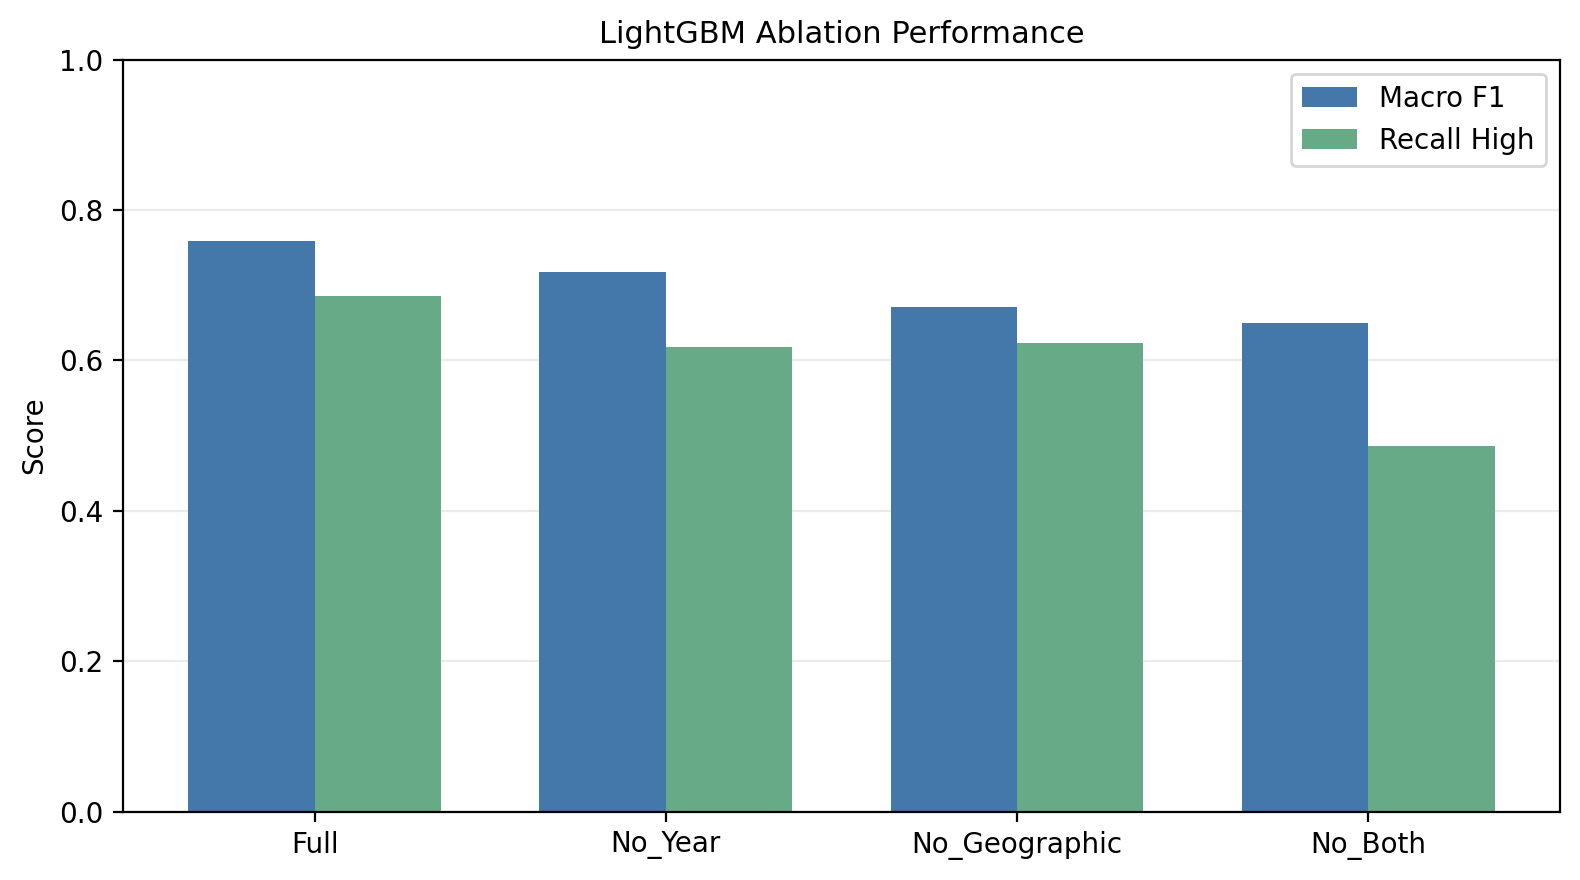

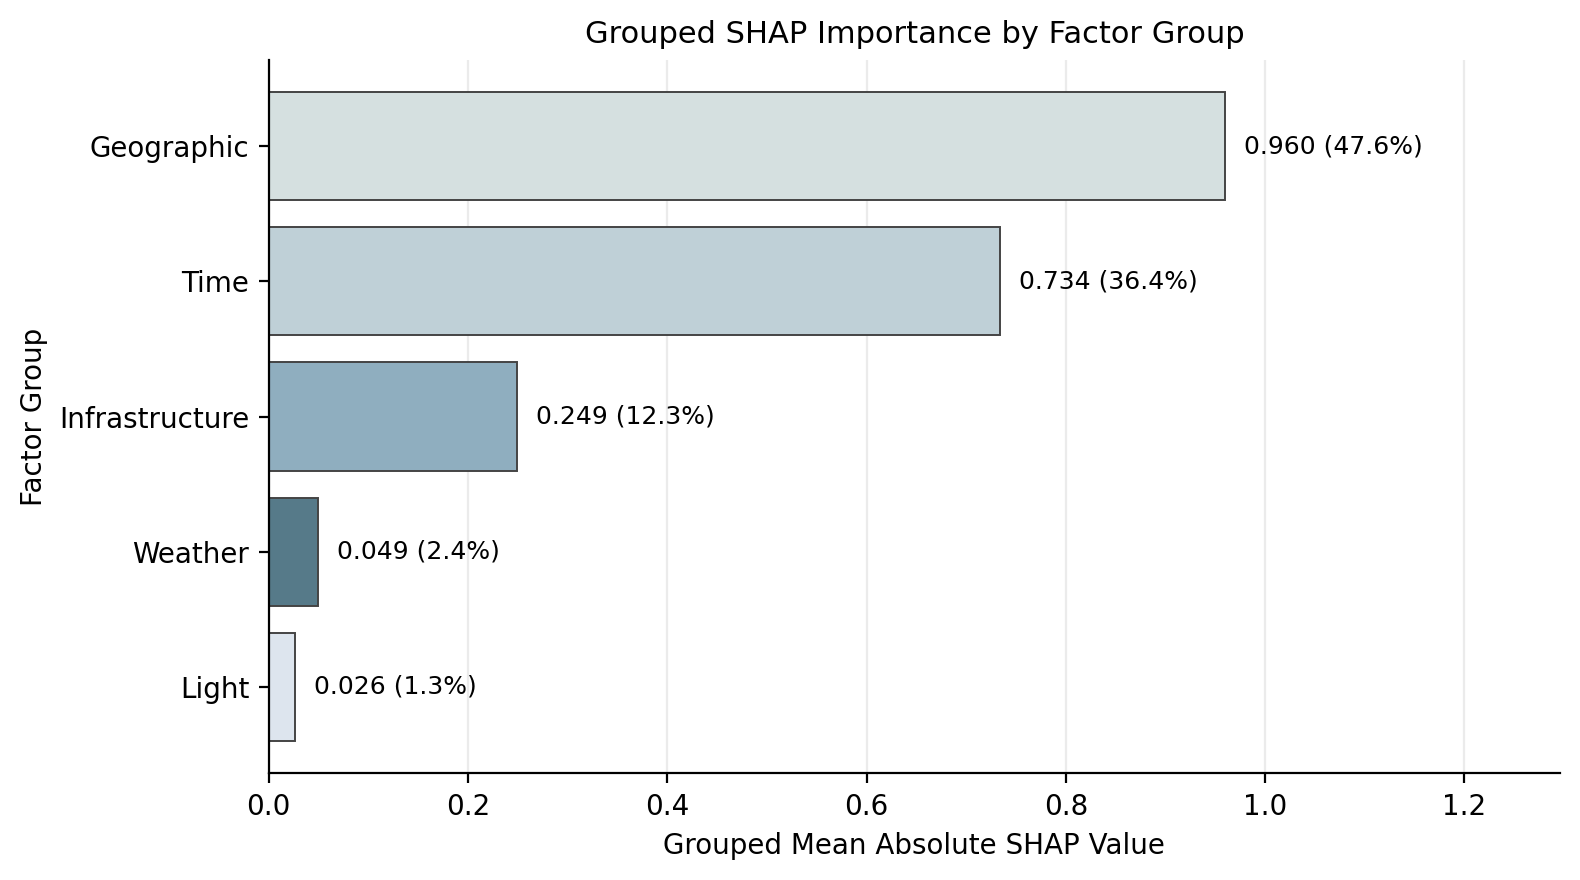

✅ Publication-ready figures saved.


In [ ]:

# 7 — ABLATION AND SHAP VISUALIZATION

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "figure.dpi": 200,
    "axes.titlesize": 11
})

# FIGURE A — Ablation performance

plot_data = ablation_table.set_index("Experiment")

fig, ax = plt.subplots(figsize=(8, 4.5))

x = np.arange(len(plot_data))
width = 0.36

ax.bar(
    x - width/2,
    plot_data["Macro_F1"],
    width,
    label="Macro F1",
    color="#4477AA"
)

ax.bar(
    x + width/2,
    plot_data["Recall_High"],
    width,
    label="Recall High",
    color="#66AA88"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_data.index)

ax.set_ylabel("Score")
ax.set_ylim(0, 1)

ax.set_title(
    "LightGBM Ablation Performance"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/ablation_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# FIGURE B — SHAP contribution by group
# Full model only (signed SHAP aggregated per sample)

group_full = (
    group_shap[
        group_shap["Experiment"] == "Full"
    ]
    .sort_values("Grouped_Net_MeanAbs")
)

color_map = {
    "Geographic": "#D5E0E0",
    "Time": "#BFD0D7",
    "Infrastructure": "#8FAEBF",
    "Weather": "#567A89",
    "Light": "#DDE5EE"
}

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    group_full["Group"],
    group_full["Grouped_Net_MeanAbs"],
    color=[
        color_map.get(g, "#AAAAAA")
        for g in group_full["Group"]
    ],
    edgecolor="#444444",
    linewidth=0.7
)

for bar, share in zip(
    bars,
    group_full["Grouped_Net_Share_%"]
):

    value = bar.get_width()

    ax.text(
        value + (
            group_full["Grouped_Net_MeanAbs"].max()
            * 0.02
        ),
        bar.get_y() + bar.get_height()/2,
        f"{value:.3f} ({share:.1f}%)",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    group_full["Grouped_Net_MeanAbs"].max() * 1.35
)

ax.set_xlabel(
    "Grouped Mean Absolute SHAP Value"
)

ax.set_ylabel("Factor Group")

ax.set_title(
    "Grouped SHAP Importance by Factor Group"
)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/group_SHAP_corrected.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Publication-ready figures saved.")


Baseline Macro F1: 0.7608163107844839

=== GROUP PERMUTATION IMPORTANCE ===


,Group,Encoded_Columns,F1_Drop_Mean,F1_Drop_Std
1,Geographic,41,0.1612,0.0040
2,Time,5,0.1436,0.0039
0,Year_only,1,0.1387,0.0057
3,Infrastructure,9,0.0244,0.0022
4,Weather,30,0.0032,0.0013
5,Light,8,0.0024,0.0009


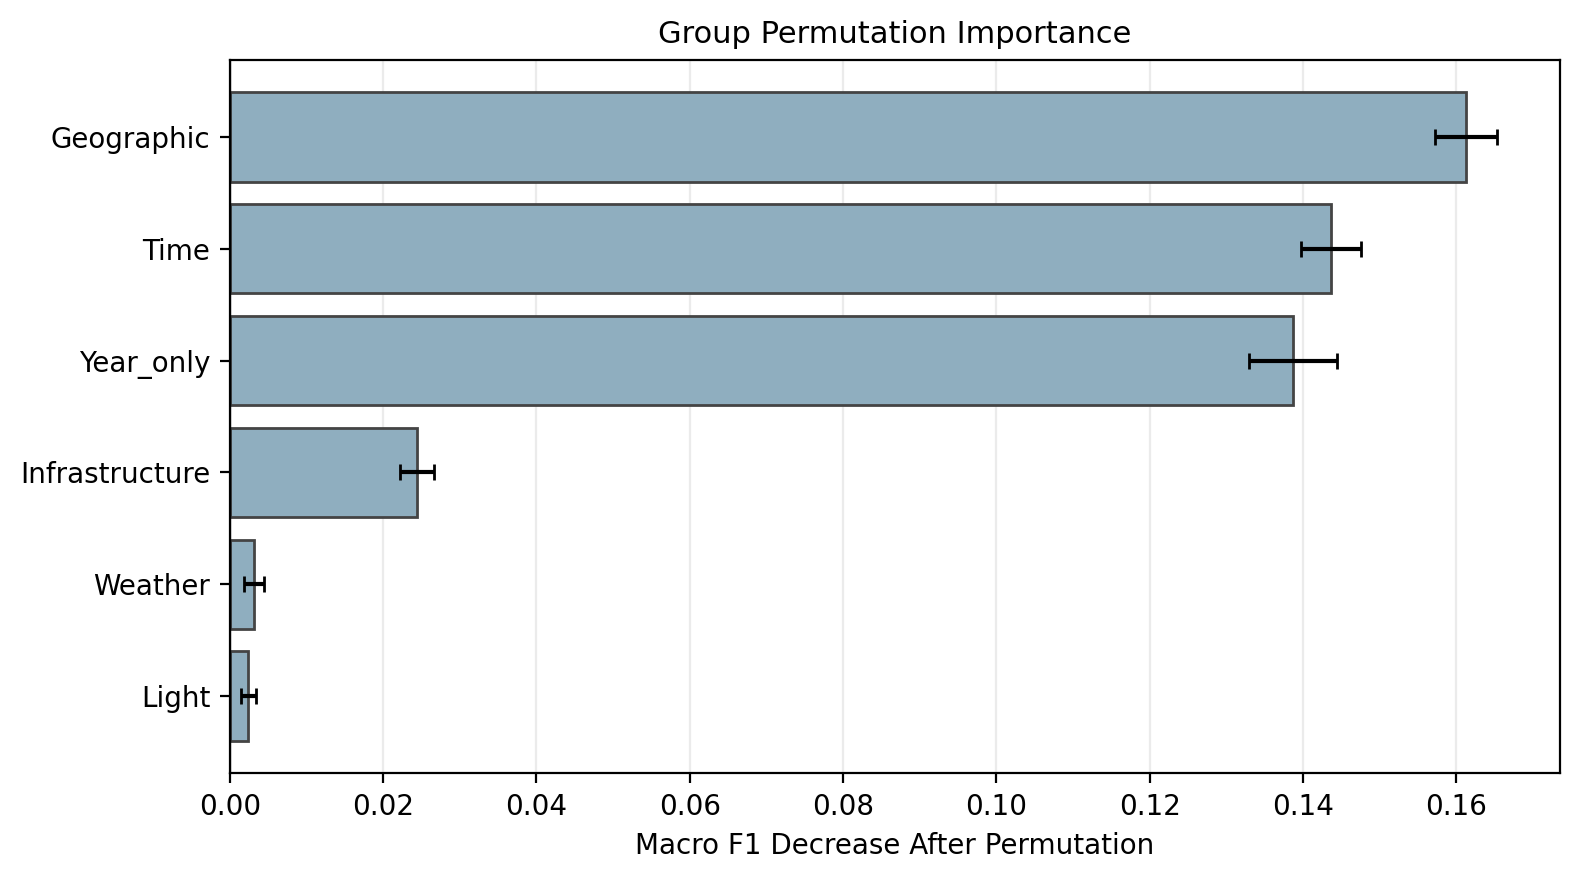

In [ ]:
# 8 — GROUP PERMUTATION IMPORTANCE

N_PERM = min(
    PERMUTATION_SAMPLE_SIZE,
    len(baseline_Xval)
)

N_REPEATS = 3

rng = np.random.default_rng(SEED)

sample_idx = rng.choice(
    len(baseline_Xval),
    size=N_PERM,
    replace=False
)

X_perm = baseline_Xval.iloc[sample_idx].copy()

y_perm = y_val.iloc[sample_idx].copy()

# 1. Baseline

pred_baseline = baseline_model.predict(X_perm)

baseline_f1 = f1_score(
    y_perm,
    pred_baseline,
    average="macro",
    zero_division=0
)

print("Baseline Macro F1:", baseline_f1)

# 2. Permute each factor group

GROUPS_TO_TEST = {
    "Year_only": ["Year"],
    **available_groups
}

permutation_results = []

origins = np.asarray(baseline_origins)

X_original = X_perm.to_numpy(
    dtype=np.float32,
    copy=True
)

for group_name, features in GROUPS_TO_TEST.items():

    mask = np.isin(origins, features)

    if mask.sum() == 0:
        continue

    score_drops = []

    for repeat in range(N_REPEATS):

        row_perm = rng.permutation(N_PERM)

        X_changed = X_original.copy()

        # Same row permutation across all group columns
        X_changed[:, mask] = (
            X_original[row_perm][:, mask]
        )

        X_changed_df = pd.DataFrame(
            X_changed,
            columns=X_perm.columns
        )

        predictions = baseline_model.predict(
            X_changed_df
        )

        permuted_f1 = f1_score(
            y_perm,
            predictions,
            average="macro",
            zero_division=0
        )

        score_drops.append(
            baseline_f1 - permuted_f1
        )

    permutation_results.append({
        "Group": group_name,
        "Encoded_Columns": int(mask.sum()),
        "F1_Drop_Mean": np.mean(score_drops),
        "F1_Drop_Std": np.std(
            score_drops,
            ddof=1
        )
    })

# 3. Results

permutation_table = pd.DataFrame(
    permutation_results
).sort_values(
    "F1_Drop_Mean",
    ascending=False
)

print("\n=== GROUP PERMUTATION IMPORTANCE ===")
display(permutation_table.round(4))

permutation_table.to_csv(
    f"{OUTPUT_DIR}/group_permutation.csv",
    index=False
)

# 4. Plot

plot_df = permutation_table.sort_values(
    "F1_Drop_Mean"
)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.barh(
    plot_df["Group"],
    plot_df["F1_Drop_Mean"],
    xerr=plot_df["F1_Drop_Std"],
    color="#8FAEBF",
    edgecolor="#444444",
    capsize=3
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel(
    "Macro F1 Decrease After Permutation"
)

ax.set_title(
    "Group Permutation Importance"
)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/group_permutation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:

# 9 — SHAP STABILITY ACROSS 3 SEEDS

STABILITY_SEEDS = [42, 52, 62]

stability_metrics = []
stability_shap = []
stability_groups = []
stability_group_net = []

for seed in STABILITY_SEEDS:

    print("\n" + "=" * 50)
    print("SEED:", seed)
    print("=" * 50)

    tr_idx, va_idx = train_test_split(
        np.arange(len(X_dev)),
        test_size=0.20,
        random_state=seed,
        stratify=y_dev
    )

    Xtr = X_dev.iloc[tr_idx].reset_index(drop=True)
    Xva = X_dev.iloc[va_idx].reset_index(drop=True)

    ytr = y_dev.iloc[tr_idx].reset_index(drop=True)
    yva = y_dev.iloc[va_idx].reset_index(drop=True)

    result = run_experiment(
        experiment_name=f"Seed_{seed}",
        features=all_features,
        Xtr=Xtr,
        ytr=ytr,
        Xva=Xva,
        yva=yva,
        seed=seed,
        compute_shap=True
    )

    stability_metrics.append({
        "Seed": seed,
        **result["Metrics"]
    })

    shap_df = result["SHAP"].copy()
    shap_df["Seed"] = seed

    stability_shap.append(shap_df)

    group_df = (
        shap_df.groupby("Group")["Mean_Abs_SHAP"]
        .sum()
    )

    group_share = (
        group_df / group_df.sum() * 100
    )

    for group, value in group_share.items():

        stability_groups.append({
            "Seed": seed,
            "Group": group,
            "SHAP_Share_%": value
        })

    # NEW: Grouped Net SHAP stability

    net_df = result["SHAP_Grouped"]

    net_total = (
        net_df["Grouped_Net_MeanAbs"].sum()
    )

    for _, row in net_df.iterrows():

        stability_group_net.append({
            "Seed": seed,
            "Group": row["Group"],
            "Grouped_Net_MeanAbs": (
                row["Grouped_Net_MeanAbs"]
            ),
            "Grouped_Net_Share_%": (
                row["Grouped_Net_MeanAbs"]
                / net_total * 100
            )
        })

    print("Top 5 features:")
    print(shap_df["Feature"].head(5).tolist())

    del result
    gc.collect()


# 1. SHAP ranking

stability_shap_df = pd.concat(
    stability_shap,
    ignore_index=True
)

rank_table = stability_shap_df.pivot(
    index="Feature",
    columns="Seed",
    values="Rank"
)

rank_table["Mean_Rank"] = (
    rank_table[STABILITY_SEEDS].mean(axis=1)
)

rank_table["Rank_Range"] = (
    rank_table[STABILITY_SEEDS].max(axis=1)
    - rank_table[STABILITY_SEEDS].min(axis=1)
)

rank_table = rank_table.sort_values(
    "Mean_Rank"
)

print("\n=== SHAP RANKING STABILITY ===")
display(rank_table.head(20))

# 2. Spearman correlation

spearman_results = []

for i, seed1 in enumerate(STABILITY_SEEDS):

    for seed2 in STABILITY_SEEDS[i+1:]:

        rho, p = spearmanr(
            rank_table[seed1],
            rank_table[seed2]
        )

        spearman_results.append({
            "Seed_1": seed1,
            "Seed_2": seed2,
            "Spearman_Rho": rho,
            "P_Value": p
        })

spearman_table = pd.DataFrame(
    spearman_results
)

print("\n=== SPEARMAN CORRELATION ===")
display(spearman_table.round(4))

# 3. Group stability

stability_group_df = pd.DataFrame(
    stability_groups
)

group_stability = (
    stability_group_df
    .groupby("Group")["SHAP_Share_%"]
    .agg(["mean", "std", "min", "max"])
    .sort_values("mean", ascending=False)
)

print(
    "\n=== GROUP SHAP STABILITY "
    "(ORIGINAL TOTAL SHAP SHARE) ==="
)

display(group_stability.round(3))

# NEW: Stability measured using grouped signed SHAP

stability_group_net_df = pd.DataFrame(
    stability_group_net
)

net_group_stability = (
    stability_group_net_df
    .groupby("Group")["Grouped_Net_Share_%"]
    .agg(["mean", "std", "min", "max"])
    .sort_values("mean", ascending=False)
)

print("\n=== GROUPED NET SHAP STABILITY ===")

display(net_group_stability.round(3))

# 4. Performance stability

stability_metric_table = pd.DataFrame(
    stability_metrics
)

print("\n=== MODEL PERFORMANCE ACROSS SEEDS ===")

display(stability_metric_table.round(4))

# 5. Save results

rank_table.to_csv(
    f"{OUTPUT_DIR}/stability_SHAP_rank.csv"
)

spearman_table.to_csv(
    f"{OUTPUT_DIR}/stability_spearman.csv",
    index=False
)

group_stability.to_csv(
    f"{OUTPUT_DIR}/stability_group_SHAP.csv"
)

stability_metric_table.to_csv(
    f"{OUTPUT_DIR}/stability_metrics.csv",
    index=False
)

# NEW: Save Grouped Net SHAP stability results
stability_group_net_df.to_csv(
    f"{OUTPUT_DIR}/stability_group_net_by_seed.csv",
    index=False
)

net_group_stability.to_csv(
    f"{OUTPUT_DIR}/stability_group_net_SHAP.csv"
)

print("\n✅ SHAP stability completed.")



SEED: 42
Top 5 features:
['Year', 'Zipcode', 'Street', 'Start_Lng', 'Month']

SEED: 52
Top 5 features:
['Year', 'Zipcode', 'Street', 'State', 'Start_Lng']

SEED: 62
Top 5 features:
['Year', 'Zipcode', 'Street', 'Start_Lng', 'State']

=== SHAP RANKING STABILITY ===


Seed,42,52,62,Mean_Rank,Rank_Range
Feature,,,,,
Year,1,1,1,1.000000,0
Zipcode,2,2,2,2.000000,0
Street,3,3,3,3.000000,0
Start_Lng,4,5,4,4.333333,1
State,6,4,5,5.000000,2
Month,5,6,6,5.666667,1
Start_Lat,7,7,7,7.000000,0
Airport_Code,8,8,8,8.000000,0
County,9,10,9,9.333333,1



=== SPEARMAN CORRELATION ===


,Seed_1,Seed_2,Spearman_Rho,P_Value
0,42,52,0.9847,0.0
1,42,62,0.9795,0.0
2,52,62,0.9655,0.0



=== GROUP SHAP STABILITY (ORIGINAL TOTAL SHAP SHARE) ===


...


=== GROUPED NET SHAP STABILITY ===


,mean,std,min,max
Group,,,,
Geographic,47.130,0.258,46.947,47.425
Time,37.801,0.583,37.404,38.470
Infrastructure,11.665,0.252,11.397,11.898
Weather,2.102,0.173,1.920,2.263
Light,1.302,0.172,1.151,1.488



=== MODEL PERFORMANCE ACROSS SEEDS ===


,Seed,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Recall_High
0,42,0.8363,0.7423,0.7796,0.7576,0.6869
1,52,0.8370,0.7430,0.7782,0.7576,0.6821
2,62,0.8366,0.7426,0.7792,0.7577,0.6852



✅ SHAP stability completed.


In [ ]:
# 10 — TEMPORAL VALIDATION
# Train: 2016–2020
# Validation: 2021 and 2022

# 1. Split by Year within development pool

train_mask = years_dev.between(2016, 2020)
val_2021_mask = years_dev == 2021
val_2022_mask = years_dev == 2022

Xtr_time = X_dev.loc[train_mask].reset_index(drop=True)
ytr_time = y_dev.loc[train_mask].reset_index(drop=True)

X21 = X_dev.loc[val_2021_mask].reset_index(drop=True)
y21 = y_dev.loc[val_2021_mask].reset_index(drop=True)

X22 = X_dev.loc[val_2022_mask].reset_index(drop=True)
y22 = y_dev.loc[val_2022_mask].reset_index(drop=True)

print("=== TEMPORAL SPLIT ===")
print("Train 2016–2020:", len(Xtr_time))
print("Validation 2021:", len(X21))
print("Validation 2022:", len(X22))

if min(len(Xtr_time), len(X21), len(X22)) == 0:
    raise ValueError(
        "Insufficient data for temporal validation."
    )

print("\nSeverity High distribution:")
print("Train:", round(ytr_time.mean()*100, 2), "%")
print("2021:", round(y21.mean()*100, 2), "%")
print("2022:", round(y22.mean()*100, 2), "%")

# 2. Temporal experiments

temporal_results = []

for name, features in EXPERIMENTS.items():

    print("\n" + "=" * 50)
    print("TEMPORAL EXPERIMENT:", name)
    print("=" * 50)

    # Preprocessing fitted only on 2016–2020
    Xtr_p, X21_p, _ = preprocess_features(
        Xtr_time,
        X21,
        features
    )

    # Fit same transformations using the same train
    Xtr_check, X22_p, _ = preprocess_features(
        Xtr_time,
        X22,
        features
    )

    assert (
        Xtr_p.columns.tolist()
        == X22_p.columns.tolist()
    )

    assert np.allclose(
        Xtr_p.to_numpy(),
        Xtr_check.to_numpy()
    ), "Training preprocessing is inconsistent."

    # Train LightGBM
    model_time = create_model(SEED)

    model_time.fit(
        Xtr_p,
        ytr_time,
        sample_weight=get_sample_weights(ytr_time)
    )

    # Evaluate on future years
    for eval_year, X_eval, y_eval in [
        (2021, X21_p, y21),
        (2022, X22_p, y22)
    ]:

        pred = model_time.predict(X_eval)

        metrics = calculate_metrics(
            y_eval,
            pred
        )

        temporal_results.append({
            "Experiment": name,
            "Evaluation_Year": eval_year,
            "N": len(y_eval),
            "High_Rate_%": y_eval.mean() * 100,
            **metrics
        })

        print(
            f"Year {eval_year} | "
            f"Macro F1 = {metrics['Macro_F1']:.4f} | "
            f"Recall High = {metrics['Recall_High']:.4f}"
        )

    del model_time, Xtr_p, Xtr_check, X21_p, X22_p
    gc.collect()

# 3. Results

temporal_table = pd.DataFrame(
    temporal_results
)

print("\n=== TEMPORAL VALIDATION RESULTS ===")
display(temporal_table.round(4))

# Compare against Full on the SAME year
temporal_full = (
    temporal_table[
        temporal_table["Experiment"] == "Full"
    ]
    .set_index("Evaluation_Year")["Macro_F1"]
)

temporal_table["Delta_vs_Full"] = (
    temporal_table["Macro_F1"]
    - temporal_table["Evaluation_Year"].map(
        temporal_full
    )
)

print("\n=== TEMPORAL COMPARISON ===")
display(temporal_table.round(4))

# 4. Save

temporal_table.to_csv(
    f"{OUTPUT_DIR}/temporal_validation.csv",
    index=False
)

print("\n✅ Temporal validation completed.")

=== TEMPORAL SPLIT ===
Train 2016–2020: 108013
Validation 2021: 40655
Validation 2022: 45067

Severity High distribution:
Train: 28.63 %
2021: 11.42 %
2022: 6.77 %

TEMPORAL EXPERIMENT: Full
Year 2021 | Macro F1 = 0.6045 | Recall High = 0.6097
Year 2022 | Macro F1 = 0.5209 | Recall High = 0.6205

TEMPORAL EXPERIMENT: No_Year
Year 2021 | Macro F1 = 0.5903 | Recall High = 0.7124
Year 2022 | Macro F1 = 0.4933 | Recall High = 0.6522

TEMPORAL EXPERIMENT: No_Geographic
Year 2021 | Macro F1 = 0.5227 | Recall High = 0.4063
Year 2022 | Macro F1 = 0.4842 | Recall High = 0.4821

TEMPORAL EXPERIMENT: No_Both
Year 2021 | Macro F1 = 0.4959 | Recall High = 0.5075
Year 2022 | Macro F1 = 0.4445 | Recall High = 0.5690

=== TEMPORAL VALIDATION RESULTS ===


,Experiment,Evaluation_Year,N,High_Rate_%,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Recall_High
0,Full,2021,40655,11.4180,0.7540,0.5978,0.6911,0.6045,0.6097
1,Full,2022,45067,6.7699,0.7067,0.5492,0.6667,0.5209,0.6205
2,No_Year,2021,40655,11.4180,0.7155,0.5975,0.7141,0.5903,0.7124
3,No_Year,2022,45067,6.7699,0.6573,0.5423,0.6550,0.4933,0.6522
4,No_Geographic,2021,40655,11.4180,0.6969,0.5351,0.5703,0.5227,0.4063
5,No_Geographic,2022,45067,6.7699,0.6776,0.5252,0.5870,0.4842,0.4821
6,No_Both,2021,40655,11.4180,0.6282,0.5327,0.5756,0.4959,0.5075
7,No_Both,2022,45067,6.7699,0.5915,0.5210,0.5811,0.4445,0.5690



=== TEMPORAL COMPARISON ===


,Experiment,Evaluation_Year,N,High_Rate_%,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Recall_High,Delta_vs_Full
0,Full,2021,40655,11.4180,0.7540,0.5978,0.6911,0.6045,0.6097,0.0000
1,Full,2022,45067,6.7699,0.7067,0.5492,0.6667,0.5209,0.6205,0.0000
2,No_Year,2021,40655,11.4180,0.7155,0.5975,0.7141,0.5903,0.7124,-0.0142
3,No_Year,2022,45067,6.7699,0.6573,0.5423,0.6550,0.4933,0.6522,-0.0277
4,No_Geographic,2021,40655,11.4180,0.6969,0.5351,0.5703,0.5227,0.4063,-0.0818
5,No_Geographic,2022,45067,6.7699,0.6776,0.5252,0.5870,0.4842,0.4821,-0.0367
6,No_Both,2021,40655,11.4180,0.6282,0.5327,0.5756,0.4959,0.5075,-0.1086
7,No_Both,2022,45067,6.7699,0.5915,0.5210,0.5811,0.4445,0.5690,-0.0765



✅ Temporal validation completed.
